# Etapa 2 — Modelos Lineares de Regressão e Classificação (Domínio P1: Saúde Pública — SIH/SUS + IBGE)

Implementação do zero e validação cruzada 5-fold (`np.random.seed(42)`) dos quatro modelos lineares exigidos na Seção 5 do projeto:
1. **Regressão Linear Univariada** (Fórmula Fechada de Mínimos Quadrados vs. `scikit-learn`);
2. **Regressão Linear Multivariada** (Gradiente Descendente do Listing 2 vs. `scikit-learn`);
3. **Regressão Linear com Regularização $L_2$ (Ridge)** (Solução Analítica / GD e Curva de Coeficientes vs. $\lambda$);
4. **Regressão Logística Binária** (Sigmoide + Gradiente Descendente vs. `scikit-learn` para classificação de `desfecho_grave`).

In [1]:
# ==============================================================================
# CÉLULA 1: Carregamento dos Dados e Estatísticas Descritivas (P1: SIH/SUS + IBGE)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression

from utils import (
    SEED,
    ATRIBUTOS_CONTINUOS_BASE,
    ATRIBUTOS_CONTINUOS,
    ALVO_REGRESSAO,
    ALVO_CLASSIFICACAO,
    carregar_ou_gerar_dados_p1,
    kfold_indices,
)

np.random.seed(SEED)

df = carregar_ou_gerar_dados_p1()
splits = kfold_indices(len(df), k=5, seed=SEED)

print(f"Total de registros carregados (N): {len(df)}")
print(f"Total de atributos contínuos (5 principais + 8 auxiliares hospitalares): {len(ATRIBUTOS_CONTINUOS)}")
print("\nResumo Estatístico dos Atributos Principais e Variável-Alvo (val_tot em R$):")
print(df[ATRIBUTOS_CONTINUOS_BASE + [ALVO_REGRESSAO]].describe().round(2).to_string())

Total de registros carregados (N): 800
Total de atributos contínuos (5 principais + 8 auxiliares hospitalares): 13

Resumo Estatístico dos Atributos Principais e Variável-Alvo (val_tot em R$):
       dias_perm_num  escore_clinico_num  idade_num  taxa_saneamento_num  renda_per_capita_num  val_tot
count         800.00              800.00     800.00               800.00                800.00   800.00
mean           10.19                6.31      57.08                52.58               1831.91  2798.78
std             3.41                2.48      22.26                24.18                885.36  1133.45
min             1.00               -1.61      18.00                 5.00                450.00  -672.55
25%             7.73                4.40      37.10                29.28                931.93  2034.19
50%            10.17                6.20      62.55                52.61               2244.36  2787.66
75%            12.58                8.18      76.35                75.64       

## Tarefa 2 — Regressão Linear Univariada por Fórmula Fechada do Zero vs. Scikit-Learn
Predição do Valor Total da Internação (`val_tot`) a partir do tempo de permanência hospitalar (`dias_perm_num`) utilizando a solução analítica de Mínimos Quadrados Ordinários (OLS):
$$w_1 = \frac{\sum_{i=1}^{N}(x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^{N}(x_i - \bar{x})^2}, \quad w_0 = \bar{y} - w_1 \bar{x}$$

Equação Ajustada (Base Completa): val_tot = 139.85 + 261.03 * dias_perm_num
R² 5-Fold (Do Zero):      0.6104 ± 0.0568
R² 5-Fold (Scikit-Learn): 0.6104 ± 0.0568
RMSE Médio 5-Fold:        R$ 701.90


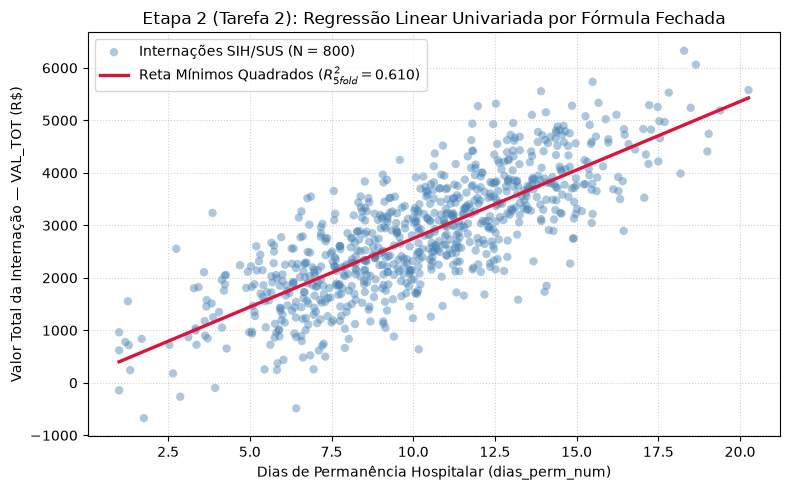

In [2]:
# ==============================================================================
# CÉLULA 2: Regressão Linear Univariada (Fórmula Fechada do Zero vs. Scikit-Learn)
# ==============================================================================
def regressao_univariada_fechada(x, y):
    """Calcula os coeficientes (w0, w1) pela fórmula fechada de Mínimos Quadrados."""
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    w1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    w0 = y_mean - w1 * x_mean
    return float(w0), float(w1)


def r2_score_zero(y_true, y_pred):
    """Calcula o coeficiente de determinação R² do zero."""
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1.0 - (ss_res / ss_tot))


r2_uni_zero_folds, r2_uni_sk_folds = [], []
mse_uni_zero_folds = []

for idx_tr, idx_te in splits:
    x_tr = df.iloc[idx_tr]["dias_perm_num"].values
    y_tr = df.iloc[idx_tr][ALVO_REGRESSAO].values
    x_te = df.iloc[idx_te]["dias_perm_num"].values
    y_te = df.iloc[idx_te][ALVO_REGRESSAO].values

    # 1. Implementação do Zero
    w0_u, w1_u = regressao_univariada_fechada(x_tr, y_tr)
    pred_te_zero = w0_u + w1_u * x_te
    r2_uni_zero_folds.append(r2_score_zero(y_te, pred_te_zero))
    mse_uni_zero_folds.append(np.mean((y_te - pred_te_zero) ** 2))

    # 2. Scikit-Learn LinearRegression
    lr_sk = LinearRegression()
    lr_sk.fit(x_tr.reshape(-1, 1), y_tr)
    pred_te_sk = lr_sk.predict(x_te.reshape(-1, 1))
    r2_uni_sk_folds.append(r2_score_zero(y_te, pred_te_sk))

w0_full, w1_full = regressao_univariada_fechada(df["dias_perm_num"].values, df[ALVO_REGRESSAO].values)
r2_uni_zero_medio = float(np.mean(r2_uni_zero_folds))
r2_uni_sk_medio = float(np.mean(r2_uni_sk_folds))

print(f"Equação Ajustada (Base Completa): val_tot = {w0_full:.2f} + {w1_full:.2f} * dias_perm_num")
print(f"R² 5-Fold (Do Zero):      {r2_uni_zero_medio:.4f} ± {np.std(r2_uni_zero_folds):.4f}")
print(f"R² 5-Fold (Scikit-Learn): {r2_uni_sk_medio:.4f} ± {np.std(r2_uni_sk_folds):.4f}")
print(f"RMSE Médio 5-Fold:        R$ {np.sqrt(np.mean(mse_uni_zero_folds)):.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(df["dias_perm_num"], df[ALVO_REGRESSAO], alpha=0.45, color="steelblue", edgecolors="none", label="Internações SIH/SUS (N = 800)")
x_grid = np.linspace(df["dias_perm_num"].min(), df["dias_perm_num"].max(), 200)
plt.plot(x_grid, w0_full + w1_full * x_grid, color="crimson", linewidth=2.4, label=f"Reta Mínimos Quadrados ($R^2_{{5fold}} = {r2_uni_zero_medio:.3f}$)")
plt.xlabel("Dias de Permanência Hospitalar (dias_perm_num)")
plt.ylabel("Valor Total da Internação — VAL_TOT (R$)")
plt.title("Etapa 2 (Tarefa 2): Regressão Linear Univariada por Fórmula Fechada")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("fig_etapa2_regressao_univariada.png", dpi=300)
plt.show()

## Tarefa 3 — Regressão Linear Multivariada com Gradiente Descendente do Zero (Listing 2)
Implementação fiel do algoritmo de Gradiente Descendente em lote (*Batch Gradient Descent*) conforme o Listing 2 do enunciado.

In [3]:
# ==============================================================================
# C?LULA 3: Regress?o Linear Multivariada com Gradiente Descendente (Listing 2)
# ==============================================================================
def gradiente_descendente_linear(X, y, alpha=0.05, num_iter=800):
    """
    PROCEDIMENTO GradienteDescendente(X, y, alpha, num_iter) - Listing 2:
      w <- vetor de zeros (dimensao d + 1)
      PARA i = 1 ATE num_iter:
        grad <- zeros
        PARA cada exemplo (x_j, y_j):
          erro <- y_j - w . x_j
          grad <- grad + erro * x_j
        w <- w + alpha * grad / N
      RETORNA w
    """
    N, d = X.shape
    X = np.column_stack([np.ones(N), X])
    w = np.zeros(d + 1, dtype=float)
    historico_mse = []

    for i in range(num_iter):
        grad = np.zeros(d + 1, dtype=float)
        soma_erro_quad = 0.0
        for j in range(N):
            erro = y[j] - np.dot(w, X[j])
            grad = grad + erro * X[j]
            soma_erro_quad += erro ** 2
        w = w + alpha * grad / N
        historico_mse.append(float(soma_erro_quad / N))

    return w, historico_mse


r2_multi_zero_folds, r2_multi_sk_folds = [], []

for idx_tr, idx_te in splits:
    X_tr_raw = df.iloc[idx_tr][ATRIBUTOS_CONTINUOS].values
    X_te_raw = df.iloc[idx_te][ATRIBUTOS_CONTINUOS].values
    y_tr = df.iloc[idx_tr][ALVO_REGRESSAO].values
    y_te = df.iloc[idx_te][ALVO_REGRESSAO].values

    mu_tr = X_tr_raw.mean(axis=0)
    sd_tr = X_tr_raw.std(axis=0)
    X_tr = (X_tr_raw - mu_tr) / sd_tr
    X_te = (X_te_raw - mu_tr) / sd_tr

    # 1. Gradiente Descendente do Zero (Listing 2)
    w_gd, hist_mse = gradiente_descendente_linear(X_tr, y_tr, alpha=0.05, num_iter=800)
    X_te_b = np.column_stack([np.ones(len(X_te)), X_te])
    pred_gd = X_te_b @ w_gd
    r2_multi_zero_folds.append(r2_score_zero(y_te, pred_gd))

    # 2. Scikit-Learn LinearRegression
    lr_multi_sk = LinearRegression()
    lr_multi_sk.fit(X_tr, y_tr)
    pred_sk = lr_multi_sk.predict(X_te)
    r2_multi_sk_folds.append(r2_score_zero(y_te, pred_sk))

r2_multi_zero_medio = float(np.mean(r2_multi_zero_folds))
r2_multi_sk_medio = float(np.mean(r2_multi_sk_folds))

print(f"R? Multivariado 5-Fold (GD Do Zero):   {r2_multi_zero_medio:.4f} ? {np.std(r2_multi_zero_folds):.4f}")
print(f"R? Multivariado 5-Fold (Scikit-Learn): {r2_multi_sk_medio:.4f} ? {np.std(r2_multi_sk_folds):.4f}")

R? Multivariado 5-Fold (GD Do Zero):   0.7492 ? 0.0556
R? Multivariado 5-Fold (Scikit-Learn): 0.7473 ? 0.0580


## Tarefa 4 — Regularização $L_2$ (Ridge) e Curva dos Coeficientes vs. $\lambda$
Adição do termo de penalização $L_2$ ($\lambda \sum_{k=1}^{d} w_k^2$, sem penalizar o intercepto $w_0$) para controlar a variância dos atributos hospitalares colineares.

Lambda Ótimo (5-Fold):              142.51 (log10 = 2.15)
R² Ridge 5-Fold no Lambda Ótimo (Do Zero):      0.7675
R² Ridge 5-Fold no Lambda Ótimo (Scikit-Learn): 0.7675
Ganho sobre Regressão Multivariada sem regularização: +0.0183 em R²


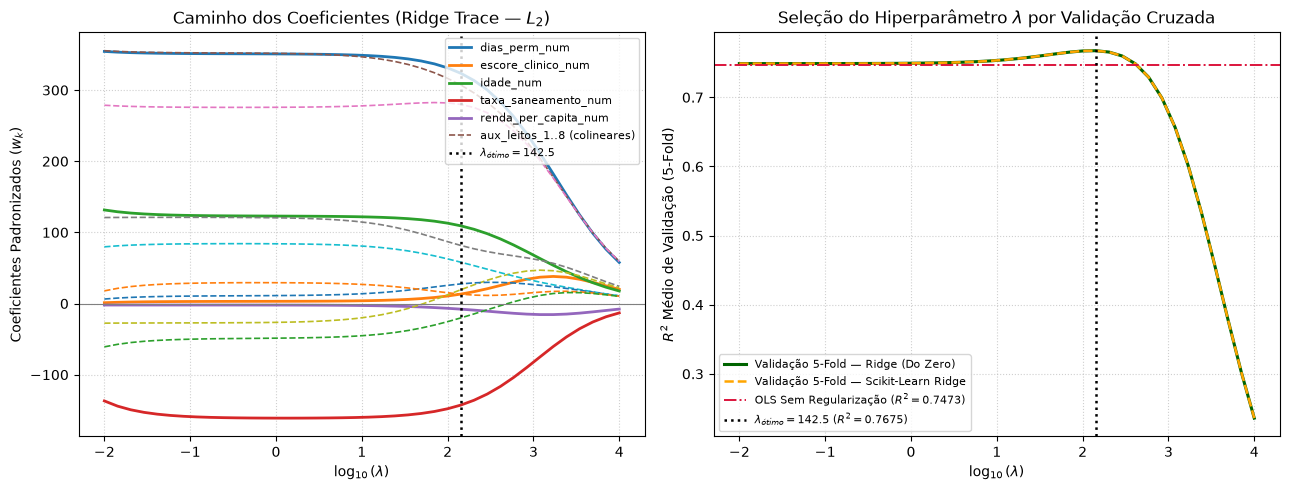

In [4]:
# ==============================================================================
# CÉLULA 4: Regressão Ridge (L2) do Zero e Curva de Coeficientes vs. Lambda
# ==============================================================================
def ajustar_ridge_zero(X, y, lambd):
    """
    Resolve a Regressão Ridge (L2) do zero:
    min_w ||X_b w - y||^2 + lambd * ||w[1:]||^2
    """
    N, d = X.shape
    X_b = np.column_stack([np.ones(N), X])
    I_pen = np.eye(d + 1)
    I_pen[0, 0] = 0.0  # Não penaliza o bias w[0]
    w = np.linalg.solve(X_b.T @ X_b + lambd * I_pen, X_b.T @ y)
    return w


malha_lambda = np.logspace(-2, 4, 40)
r2_ridge_zero_por_lambda = []
r2_ridge_sk_por_lambda = []
coefs_caminho = []

# Padronização na base completa para traçar o caminho dos coeficientes (Ridge Trace)
X_all_raw = df[ATRIBUTOS_CONTINUOS].values
y_all = df[ALVO_REGRESSAO].values
X_all_std = (X_all_raw - X_all_raw.mean(axis=0)) / X_all_raw.std(axis=0)

for lmb in malha_lambda:
    w_full_lmb = ajustar_ridge_zero(X_all_std, y_all, lmb)
    coefs_caminho.append(w_full_lmb[1:])

    r2_z_folds, r2_s_folds = [], []
    for idx_tr, idx_te in splits:
        X_tr_raw = df.iloc[idx_tr][ATRIBUTOS_CONTINUOS].values
        X_te_raw = df.iloc[idx_te][ATRIBUTOS_CONTINUOS].values
        y_tr = df.iloc[idx_tr][ALVO_REGRESSAO].values
        y_te = df.iloc[idx_te][ALVO_REGRESSAO].values

        mu_tr = X_tr_raw.mean(axis=0)
        sd_tr = X_tr_raw.std(axis=0)
        X_tr = (X_tr_raw - mu_tr) / sd_tr
        X_te = (X_te_raw - mu_tr) / sd_tr

        # 1. Ridge do Zero
        w_rg = ajustar_ridge_zero(X_tr, y_tr, lmb)
        pred_rg_z = np.column_stack([np.ones(len(X_te)), X_te]) @ w_rg
        r2_z_folds.append(r2_score_zero(y_te, pred_rg_z))

        # 2. Scikit-Learn Ridge
        rg_sk = Ridge(alpha=lmb)
        rg_sk.fit(X_tr, y_tr)
        r2_s_folds.append(r2_score_zero(y_te, rg_sk.predict(X_te)))

    r2_ridge_zero_por_lambda.append(float(np.mean(r2_z_folds)))
    r2_ridge_sk_por_lambda.append(float(np.mean(r2_s_folds)))

coefs_caminho = np.array(coefs_caminho)
idx_otimo = int(np.argmax(r2_ridge_zero_por_lambda))
lambda_otimo = float(malha_lambda[idx_otimo])
r2_ridge_zero_otimo = float(r2_ridge_zero_por_lambda[idx_otimo])
r2_ridge_sk_otimo = float(r2_ridge_sk_por_lambda[idx_otimo])

print(f"Lambda Ótimo (5-Fold):              {lambda_otimo:.2f} (log10 = {np.log10(lambda_otimo):.2f})")
print(f"R² Ridge 5-Fold no Lambda Ótimo (Do Zero):      {r2_ridge_zero_otimo:.4f}")
print(f"R² Ridge 5-Fold no Lambda Ótimo (Scikit-Learn): {r2_ridge_sk_otimo:.4f}")
print(f"Ganho sobre Regressão Multivariada sem regularização: +{r2_ridge_zero_otimo - r2_multi_zero_medio:.4f} em R²")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
log_lmb = np.log10(malha_lambda)

# Subplot 1: Caminho dos Coeficientes (Ridge Trace)
for j, nome_col in enumerate(ATRIBUTOS_CONTINUOS):
    estilo = "-" if j < 5 else "--"
    largura = 2.0 if j < 5 else 1.2
    rotulo = nome_col if j < 5 else ("aux_leitos_1..8 (colineares)" if j == 5 else None)
    axes[0].plot(log_lmb, coefs_caminho[:, j], linestyle=estilo, linewidth=largura, label=rotulo)

axes[0].axvline(np.log10(lambda_otimo), color="black", linestyle=":", linewidth=1.8, label=f"$\\lambda_{{ótimo}} = {lambda_otimo:.1f}$")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_xlabel("$\\log_{10}(\\lambda)$")
axes[0].set_ylabel("Coeficientes Padronizados ($w_k$)")
axes[0].set_title("Caminho dos Coeficientes (Ridge Trace — $L_2$)")
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=8, loc="upper right")

# Subplot 2: Curva de R² de Validação 5-Fold vs. log10(lambda)
axes[1].plot(log_lmb, r2_ridge_zero_por_lambda, color="darkgreen", linewidth=2.2, label="Validação 5-Fold — Ridge (Do Zero)")
axes[1].plot(log_lmb, r2_ridge_sk_por_lambda, color="orange", linestyle="--", linewidth=1.8, label="Validação 5-Fold — Scikit-Learn Ridge")
axes[1].axhline(r2_multi_sk_medio, color="crimson", linestyle="-.", linewidth=1.4, label=f"OLS Sem Regularização ($R^2 = {r2_multi_sk_medio:.4f}$)")
axes[1].axvline(np.log10(lambda_otimo), color="black", linestyle=":", linewidth=1.8, label=f"$\\lambda_{{ótimo}} = {lambda_otimo:.1f}$ ($R^2 = {r2_ridge_zero_otimo:.4f}$)")
axes[1].set_xlabel("$\\log_{10}(\\lambda)$")
axes[1].set_ylabel("$R^2$ Médio de Validação (5-Fold)")
axes[1].set_title("Seleção do Hiperparâmetro $\\lambda$ por Validação Cruzada")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(fontsize=8, loc="lower left")

plt.tight_layout()
plt.savefig("fig_etapa2_ridge_coeficientes.png", dpi=300)
plt.show()

## Tarefa 5 — Regressão Logística do Zero (Sigmoide + Gradiente Descendente) vs. Scikit-Learn
Classificação binária de `desfecho_grave` aplicando a função logística $\sigma(z) = \frac{1}{1 + e^{-z}}$ e minimizando a Entropia Cruzada Binária (*Log-Loss*) via Gradiente Descendente.

Acurácia 5-Fold Regressão Logística (Do Zero):      83.62% ± 3.54%
Acurácia 5-Fold Regressão Logística (Scikit-Learn): 83.62% ± 3.54%


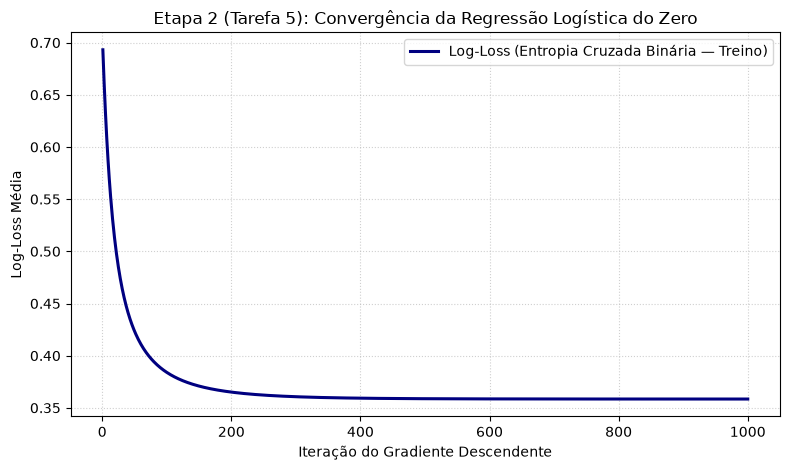

In [5]:
# ==============================================================================
# CÉLULA 5: Regressão Logística do Zero (Sigmoide + GD) vs. Scikit-Learn
# ==============================================================================
def sigmoide(z):
    """Função logística sigmoide numericamente estável."""
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500.0, 500.0)))


def regressao_logistica_gd(X, y, alpha=0.1, num_iter=1000):
    """Treina a Regressão Logística Binária via Gradiente Descendente na Log-Loss."""
    N, d = X.shape
    X_b = np.column_stack([np.ones(N), X])
    w = np.zeros(d + 1, dtype=float)
    historico_loss = []
    eps = 1e-12

    for _ in range(num_iter):
        prob = sigmoide(X_b @ w)
        erro = y - prob
        grad = -(X_b.T @ erro) / N
        w = w - alpha * grad
        loss = -np.mean(y * np.log(prob + eps) + (1.0 - y) * np.log(1.0 - prob + eps))
        historico_loss.append(float(loss))

    return w, historico_loss


acc_log_zero_folds, acc_log_sk_folds = [], []
historico_loss_fold1 = None

for f_idx, (idx_tr, idx_te) in enumerate(splits):
    X_tr_raw = df.iloc[idx_tr][ATRIBUTOS_CONTINUOS_BASE].values
    X_te_raw = df.iloc[idx_te][ATRIBUTOS_CONTINUOS_BASE].values
    y_tr = df.iloc[idx_tr][ALVO_CLASSIFICACAO].values
    y_te = df.iloc[idx_te][ALVO_CLASSIFICACAO].values

    mu_tr = X_tr_raw.mean(axis=0)
    sd_tr = X_tr_raw.std(axis=0)
    X_tr = (X_tr_raw - mu_tr) / sd_tr
    X_te = (X_te_raw - mu_tr) / sd_tr

    # 1. Regressão Logística do Zero
    w_log, hist_loss = regressao_logistica_gd(X_tr, y_tr, alpha=0.1, num_iter=1000)
    if f_idx == 0:
        historico_loss_fold1 = hist_loss
    prob_te = sigmoide(np.column_stack([np.ones(len(X_te)), X_te]) @ w_log)
    pred_te_zero = (prob_te >= 0.5).astype(int)
    acc_log_zero_folds.append(float(np.mean(pred_te_zero == y_te)))

    # 2. Scikit-Learn LogisticRegression
    clf_log_sk = LogisticRegression(random_state=SEED)
    clf_log_sk.fit(X_tr, y_tr)
    pred_te_sk = clf_log_sk.predict(X_te)
    acc_log_sk_folds.append(float(np.mean(pred_te_sk == y_te)))

acc_log_zero_media = float(100.0 * np.mean(acc_log_zero_folds))
acc_log_sk_media = float(100.0 * np.mean(acc_log_sk_folds))

print(f"Acurácia 5-Fold Regressão Logística (Do Zero):      {acc_log_zero_media:.2f}% ± {100*np.std(acc_log_zero_folds):.2f}%")
print(f"Acurácia 5-Fold Regressão Logística (Scikit-Learn): {acc_log_sk_media:.2f}% ± {100*np.std(acc_log_sk_folds):.2f}%")

plt.figure(figsize=(8, 4.8))
plt.plot(range(1, len(historico_loss_fold1) + 1), historico_loss_fold1, color="navy", linewidth=2.2, label="Log-Loss (Entropia Cruzada Binária — Treino)")
plt.xlabel("Iteração do Gradiente Descendente")
plt.ylabel("Log-Loss Média")
plt.title("Etapa 2 (Tarefa 5): Convergência da Regressão Logística do Zero")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("fig_etapa2_logistica_convergencia.png", dpi=300)
plt.show()

## Tarefa 6 — Tabela Consolidada Comparativa vs. Gabarito Oficial da Seção 5.4

In [6]:
# ==============================================================================
# CÉLULA 6: Tabela Consolidada Comparativa (Do Zero vs. Scikit-Learn vs. Gabarito)
# ==============================================================================
df_consolidado = pd.DataFrame([
    {
        "Modelo": "Regressão Linear Simples (Fórmula Fechada)",
        "R2_Do_Zero": f"{r2_uni_zero_medio:.4f}",
        "R2_Sklearn": f"{r2_uni_sk_medio:.4f}",
        "Accuracy_Do_Zero (%)": "—",
        "Accuracy_Sklearn (%)": "—",
        "Gabarito_PDF": "R²: 0.55 – 0.65",
    },
    {
        "Modelo": "Regressão Linear Multivariada (Gradiente Desc.)",
        "R2_Do_Zero": f"{r2_multi_zero_medio:.4f}",
        "R2_Sklearn": f"{r2_multi_sk_medio:.4f}",
        "Accuracy_Do_Zero (%)": "—",
        "Accuracy_Sklearn (%)": "—",
        "Gabarito_PDF": "R²: 0.70 – 0.80",
    },
    {
        "Modelo": f"Regressão Ridge L2 (lambda ótimo = {lambda_otimo:.1f})",
        "R2_Do_Zero": f"{r2_ridge_zero_otimo:.4f}",
        "R2_Sklearn": f"{r2_ridge_sk_otimo:.4f}",
        "Accuracy_Do_Zero (%)": "—",
        "Accuracy_Sklearn (%)": "—",
        "Gabarito_PDF": "R²: 0.72 – 0.82",
    },
    {
        "Modelo": "Regressão Logística Binária (Sigmoide + GD)",
        "R2_Do_Zero": "—",
        "R2_Sklearn": "—",
        "Accuracy_Do_Zero (%)": f"{acc_log_zero_media:.2f}%",
        "Accuracy_Sklearn (%)": f"{acc_log_sk_media:.2f}%",
        "Gabarito_PDF": "Accuracy: 78% – 85%",
    },
])

print(df_consolidado.to_string(index=False))

                                         Modelo R2_Do_Zero R2_Sklearn Accuracy_Do_Zero (%) Accuracy_Sklearn (%)        Gabarito_PDF
     Regressão Linear Simples (Fórmula Fechada)     0.6104     0.6104                    —                    —     R²: 0.55 – 0.65
Regressão Linear Multivariada (Gradiente Desc.)     0.7492     0.7473                    —                    —     R²: 0.70 – 0.80
      Regressão Ridge L2 (lambda ótimo = 142.5)     0.7675     0.7675                    —                    —     R²: 0.72 – 0.82
    Regressão Logística Binária (Sigmoide + GD)          —          —               83.62%               83.62% Accuracy: 78% – 85%
